In [1]:
import numpy as np
import pandas as pd
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

In [2]:
def load_data():
    train = pd.read_csv('fraudTrain.csv')
    test = pd.read_csv('fraudTest.csv')
    return train, test

def anonymise_and_trim(train, test):
    all_cards = pd.concat([train['cc_num'], test['cc_num']]).unique()
    card_map = {card: f"User_{i+1}" for i, card in enumerate(all_cards)}
    train['user_id'] = train['cc_num'].map(card_map)
    test['user_id'] = test['cc_num'].map(card_map)
    pd.Series(card_map).rename('user_id').to_csv('card_lookup_PRIVATE.csv')

    keep = ['user_id', 'trans_date_trans_time', 'amt', 'lat', 'long',
            'merch_lat', 'merch_long', 'category', 'is_fraud']
    train = train[keep].copy()
    test = test[keep].copy()
    train['trans_date_trans_time'] = pd.to_datetime(train['trans_date_trans_time'])
    test['trans_date_trans_time'] = pd.to_datetime(test['trans_date_trans_time'])
    return train, test

def engineer_features(train, test):
    def add_basic(df):
        df['hour'] = df['trans_date_trans_time'].dt.hour
        df['dayofweek'] = df['trans_date_trans_time'].dt.dayofweek
        p1, p2 = np.radians(df['lat']), np.radians(df['merch_lat'])
        dl = np.radians(df['merch_long'] - df['long'])
        a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2)**2
        df['dist_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
        return df

    train = add_basic(train)
    test = add_basic(test)

    normal = train[train['is_fraud'] == 0]
    base = normal.groupby('user_id').agg(
        amt_mean=('amt', 'mean'), amt_std=('amt', 'std'),
        dist_mean=('dist_km', 'mean'), dist_std=('dist_km', 'std')).reset_index()

    g = {'amt_mean': normal['amt'].mean(), 'amt_std': normal['amt'].std(),
         'dist_mean': normal['dist_km'].mean(), 'dist_std': normal['dist_km'].std()}
    for c in ['amt_std', 'dist_std']:
        base[c] = base[c].replace(0, np.nan).fillna(g[c])

    hf = (normal.groupby(['user_id', 'hour']).size() /
          normal.groupby('user_id').size()).rename('hour_freq').reset_index()

    def add_deviation(df):
        df = df.merge(base, on='user_id', how='left')
        for c in g:
            df[c] = df[c].fillna(g[c])
        df = df.merge(hf, on=['user_id', 'hour'], how='left')
        known = df['user_id'].isin(base['user_id'])
        df['hour_freq'] = df['hour_freq'].fillna(0)
        df.loc[~known, 'hour_freq'] = 1 / 24
        df['amt_z'] = (df['amt'] - df['amt_mean']) / df['amt_std']
        df['dist_z'] = (df['dist_km'] - df['dist_mean']) / df['dist_std']
        df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 3)).astype(int)
        df['log_amt'] = np.log1p(df['amt'])
        return df

    train = add_deviation(train)
    test = add_deviation(test)
    return train, test, base, g, hf

def encode_scale_resample(train, test):
    num_cols = ['log_amt', 'amt_z', 'dist_km', 'dist_z', 'hour_freq']
    X_train = pd.concat([train[num_cols + ['is_night']],
                         pd.get_dummies(train['category'], prefix='cat', dtype=int)], axis=1)
    X_test = pd.concat([test[num_cols + ['is_night']],
                        pd.get_dummies(test['category'], prefix='cat', dtype=int)], axis=1)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
    y_train, y_test = train['is_fraud'], test['is_fraud']

    scaler = StandardScaler().fit(X_train[num_cols])
    X_train[num_cols] = scaler.transform(X_train[num_cols])
    X_test[num_cols] = scaler.transform(X_test[num_cols])

    X_res, y_res = SMOTE(sampling_strategy=0.1, random_state=42).fit_resample(X_train, y_train)
    return X_res, y_res, X_test, y_test, scaler, num_cols, list(X_train.columns)

In [3]:
train, test = load_data()
train, test = anonymise_and_trim(train, test)
train, test, base, g, hf = engineer_features(train, test)
X_res, y_res, X_test_s, y_test, scaler, num_cols, feature_columns = encode_scale_resample(train, test)

print(X_res.shape, X_test_s.shape)

(1418085, 20) (555719, 20)


In [4]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=200, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_res, y_res)
    preds = model.predict(X_test_s)
    probs = model.predict_proba(X_test_s)[:, 1]
    results[name] = {
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds),
        'AUC-ROC': roc_auc_score(y_test, probs),
    }

results_df = pd.DataFrame(results).T
print(results_df)

                     Precision    Recall        F1   AUC-ROC
Logistic Regression   0.297426  0.581818  0.393629  0.934359
Random Forest         0.587571  0.824242  0.686069  0.989863
XGBoost               0.439944  0.886247  0.587999  0.997151
Neural Network        0.404432  0.884848  0.555133  0.997075


In [5]:
neg, pos = y_res.value_counts()
weight = neg / pos

xgb_weighted = XGBClassifier(eval_metric='logloss', random_state=42, scale_pos_weight=weight)
xgb_weighted.fit(X_res, y_res)
preds_w = xgb_weighted.predict(X_test_s)
probs_w = xgb_weighted.predict_proba(X_test_s)[:, 1]

comparison = pd.DataFrame({
    'XGBoost (SMOTE only)': results['XGBoost'],
    'XGBoost (SMOTE + weighted)': {
        'Precision': precision_score(y_test, preds_w),
        'Recall': recall_score(y_test, preds_w),
        'F1': f1_score(y_test, preds_w),
        'AUC-ROC': roc_auc_score(y_test, probs_w),
    }
}).T
print(comparison)

                            Precision    Recall        F1   AUC-ROC
XGBoost (SMOTE only)         0.439944  0.886247  0.587999  0.997151
XGBoost (SMOTE + weighted)   0.198772  0.950583  0.328791  0.997064


In [6]:
sample_idx = X_res.sample(200_000, random_state=42).index
X_tune, y_tune = X_res.loc[sample_idx], y_res.loc[sample_idx]

param_dist = {'max_depth': [3, 5, 7], 'n_estimators': [100, 200, 300], 'learning_rate': [0.05, 0.1, 0.2]}
search = RandomizedSearchCV(XGBClassifier(eval_metric='logloss', random_state=42),
                             param_distributions=param_dist, n_iter=8, cv=3,
                             scoring='recall', random_state=42, n_jobs=-1)
search.fit(X_tune, y_tune)
print(search.best_params_)

xgb_tuned = XGBClassifier(eval_metric='logloss', random_state=42, **search.best_params_)
xgb_tuned.fit(X_res, y_res)
preds_t = xgb_tuned.predict(X_test_s)
probs_t = xgb_tuned.predict_proba(X_test_s)[:, 1]

print(precision_score(y_test, preds_t), recall_score(y_test, preds_t),
      f1_score(y_test, preds_t), roc_auc_score(y_test, probs_t))

{'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.1}
0.4586647384912027 0.8871794871794871 0.6047028916428344 0.9972803635166752


In [7]:
joblib.dump(xgb_tuned, 'xgb_fraud_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(feature_columns, 'feature_columns.pkl')
joblib.dump(num_cols, 'num_cols.pkl')
joblib.dump(base, 'user_baselines.pkl')
joblib.dump(g, 'global_baseline.pkl')
joblib.dump(hf, 'hour_freq.pkl')

['hour_freq.pkl']

In [8]:
def score_transaction(user_id, amt, timestamp, cust_lat, cust_long, merch_lat, merch_long, category):
    timestamp = pd.to_datetime(timestamp)
    hour = timestamp.hour

    p1, p2 = np.radians(cust_lat), np.radians(merch_lat)
    dl = np.radians(merch_long - cust_long)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2)**2
    dist_km = 6371 * 2 * np.arcsin(np.sqrt(a))

    if user_id in base['user_id'].values:
        row = base[base['user_id'] == user_id].iloc[0]
        amt_mean, amt_std = row['amt_mean'], row['amt_std']
        dist_mean, dist_std = row['dist_mean'], row['dist_std']
        hf_match = hf[(hf['user_id'] == user_id) & (hf['hour'] == hour)]
        hour_freq = hf_match['hour_freq'].values[0] if len(hf_match) else 0
    else:
        amt_mean, amt_std = g['amt_mean'], g['amt_std']
        dist_mean, dist_std = g['dist_mean'], g['dist_std']
        hour_freq = 1 / 24

    amt_z = (amt - amt_mean) / amt_std
    dist_z = (dist_km - dist_mean) / dist_std
    is_night = int(hour >= 22 or hour <= 3)
    log_amt = np.log1p(amt)

    row_dict = {'log_amt': log_amt, 'amt_z': amt_z, 'dist_km': dist_km,
                'dist_z': dist_z, 'hour_freq': hour_freq, 'is_night': is_night}
    for col in feature_columns:
        if col.startswith('cat_'):
            row_dict[col] = 1 if col == f'cat_{category}' else 0

    X_new = pd.DataFrame([row_dict]).reindex(columns=feature_columns, fill_value=0)
    X_new[num_cols] = scaler.transform(X_new[num_cols])

    prob = xgb_tuned.predict_proba(X_new)[0, 1]
    verdict = 'FRAUD' if prob >= 0.5 else 'legitimate'
    return prob, verdict

In [9]:
prob, verdict = score_transaction(
    user_id='User_1', amt=500, timestamp='2020-08-15 02:30:00',
    cust_lat=36.0788, cust_long=-81.1781,
    merch_lat=36.05, merch_long=-81.20, category='shopping_net'
)
print(prob, verdict)

0.258425 legitimate


In [10]:
preds = xgb_tuned.predict(X_test_s)
probs = xgb_tuned.predict_proba(X_test_s)[:, 1]

print('Precision:', precision_score(y_test, preds))
print('Recall:', recall_score(y_test, preds))
print('F1:', f1_score(y_test, preds))
print('AUC-ROC:', roc_auc_score(y_test, probs))

Precision: 0.4586647384912027
Recall: 0.8871794871794871
F1: 0.6047028916428344
AUC-ROC: 0.9972803635166752


In [11]:
sample = test[test['is_fraud'] == 0].sample(1).iloc[0]
prob, verdict = score_transaction(
    user_id=sample['user_id'], amt=sample['amt'], timestamp=sample['trans_date_trans_time'],
    cust_lat=sample['lat'], cust_long=sample['long'],
    merch_lat=sample['merch_lat'], merch_long=sample['merch_long'], category=sample['category']
)
print('Predicted:', prob, verdict, '| Actual: legitimate')

Predicted: 0.0005027913 legitimate | Actual: legitimate


In [12]:
sample = test[test['is_fraud'] == 1].sample(1).iloc[0]
prob, verdict = score_transaction(
    user_id=sample['user_id'], amt=sample['amt'], timestamp=sample['trans_date_trans_time'],
    cust_lat=sample['lat'], cust_long=sample['long'],
    merch_lat=sample['merch_lat'], merch_long=sample['merch_long'], category=sample['category']
)
print('Predicted:', prob, verdict, '| Actual: FRAUD')

Predicted: 0.10706098 legitimate | Actual: FRAUD


In [13]:
user_id = 'User_1'

profile = base[base['user_id'] == user_id].iloc[0]
print(user_id, 'baseline:')
print('Typical amount: R', round(profile['amt_mean'], 2), '+/- R', round(profile['amt_std'], 2))
print('Typical distance from home:', round(profile['dist_mean'], 1), 'km')

user_txns = test[test['user_id'] == user_id][['trans_date_trans_time', 'amt', 'dist_km', 'is_fraud']]
print(user_txns)

User_1 baseline:
Typical amount: R 87.39 +/- R 126.6
Typical distance from home: 78.0 km
       trans_date_trans_time     amt     dist_km  is_fraud
862      2020-06-21 17:09:25   24.98   47.637977         0
1640     2020-06-21 21:47:11   21.42   48.648617         0
1734     2020-06-21 22:22:05  150.87   90.372969         0
1927     2020-06-21 23:27:13   10.10  127.476823         0
2493     2020-06-22 03:47:46   59.08   52.771958         0
...                      ...     ...         ...       ...
552169   2020-12-30 22:56:28   35.80   38.876536         0
552922   2020-12-31 05:30:18   61.95  106.235969         0
554518   2020-12-31 17:04:40   26.63   79.447463         0
554688   2020-12-31 17:58:05   77.79   32.982066         0
554735   2020-12-31 18:15:17  289.43   31.905171         0

[899 rows x 4 columns]


In [14]:
prob, verdict = score_transaction(
    user_id='User_1', amt=350, timestamp='2020-08-15 23:30:00',
    cust_lat=18.8588, cust_long=-56.1781,
    merch_lat=36.05, merch_long=-81.20, category='shopping_net'
)
print(f'{prob:.6f}', verdict)

0.001164 legitimate


In [15]:
test_amt, test_time = 500, '2020-08-15 02:30:00'
test_merch_lat, test_merch_long = 36.05, -81.20

for uid in ['User_8', 'User_155', 'User_305']:
    u = base[base['user_id'] == uid].iloc[0]
    prob, verdict = score_transaction(
        user_id=uid, amt=test_amt, timestamp=test_time,
        cust_lat=u['dist_mean'], cust_long=0,
        merch_lat=test_merch_lat, merch_long=test_merch_long, category='shopping_net'
    )
    print(uid, '| typical amount R', round(u['amt_mean'], 2), '| verdict:', verdict, round(prob, 3))

User_8 | typical amount R 65.34 | verdict: legitimate 0.001
User_155 | typical amount R 59.38 | verdict: legitimate 0.001
User_305 | typical amount R 57.17 | verdict: legitimate 0.008


In [16]:
def user_profile(user_id):
    row = base[base['user_id'] == user_id].iloc[0]
    home = train[train['user_id'] == user_id].iloc[0]
    fraud_count = train[(train['user_id'] == user_id) & (train['is_fraud'] == 1)].shape[0]
    return {
        'user_id': user_id,
        'home_lat': home['lat'], 'home_long': home['long'],
        'typical_amt': round(row['amt_mean'], 2),
        'amt_std': round(row['amt_std'], 2),
        'typical_dist_km': round(row['dist_mean'], 1),
        'num_fraud_cases_in_train': fraud_count,
    }

def compare_users_on_same_transaction(user_ids, amt, timestamp, merch_lat, merch_long, category):
    for uid in user_ids:
        p = user_profile(uid)
        prob, verdict = score_transaction(
            user_id=uid, amt=amt, timestamp=timestamp,
            cust_lat=p['home_lat'], cust_long=p['home_long'],
            merch_lat=merch_lat, merch_long=merch_long, category=category
        )
        print(uid, '| typical spend R', p['typical_amt'], '+/- R', p['amt_std'],
              '| this transaction: R', amt, '-> verdict:', verdict, round(prob, 3))

In [17]:
sample_users = base['user_id'].sample(5, random_state=1).tolist()
for uid in sample_users:
    print(user_profile(uid))

{'user_id': 'User_716', 'home_lat': np.float64(43.7557), 'home_long': np.float64(-97.5936), 'typical_amt': np.float64(59.34), 'amt_std': np.float64(139.64), 'typical_dist_km': np.float64(74.4), 'num_fraud_cases_in_train': 16}
{'user_id': 'User_329', 'home_lat': np.float64(31.3833), 'home_long': np.float64(-95.0619), 'typical_amt': np.float64(59.85), 'amt_std': np.float64(115.68), 'typical_dist_km': np.float64(79.4), 'num_fraud_cases_in_train': 0}
{'user_id': 'User_882', 'home_lat': np.float64(40.8496), 'home_long': np.float64(-80.1381), 'typical_amt': np.float64(57.99), 'amt_std': np.float64(70.47), 'typical_dist_km': np.float64(74.2), 'num_fraud_cases_in_train': 7}
{'user_id': 'User_227', 'home_lat': np.float64(39.013000000000005), 'home_long': np.float64(-86.5457), 'typical_amt': np.float64(59.22), 'amt_std': np.float64(105.7), 'typical_dist_km': np.float64(75.5), 'num_fraud_cases_in_train': 8}
{'user_id': 'User_677', 'home_lat': np.float64(44.8021), 'home_long': np.float64(-122.7624

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

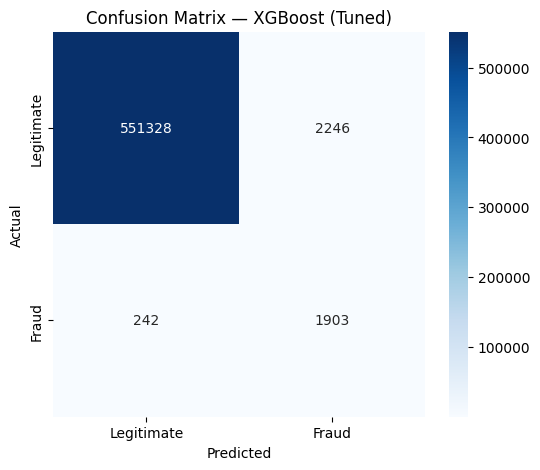

In [19]:
cm = confusion_matrix(y_test, preds_t)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — XGBoost (Tuned)')
plt.show()

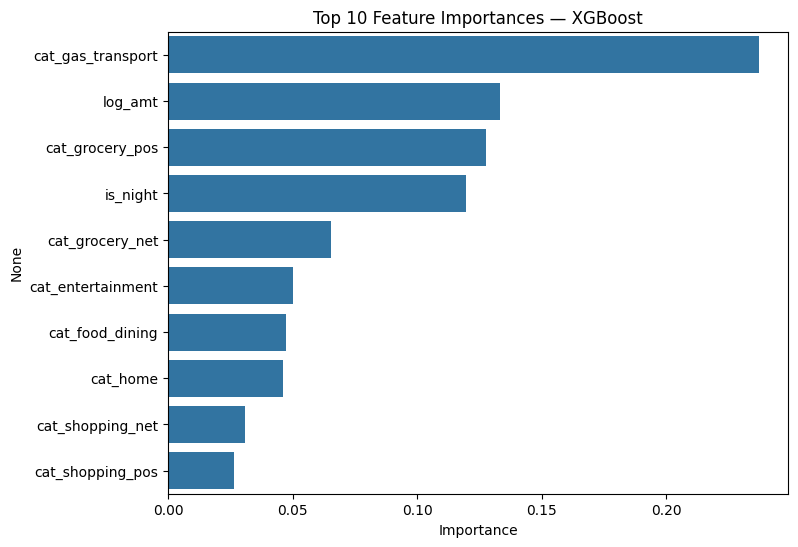

In [20]:
importances = pd.Series(xgb_tuned.feature_importances_, index=feature_columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values[:10], y=importances.index[:10])
plt.xlabel('Importance')
plt.title('Top 10 Feature Importances — XGBoost')
plt.show()

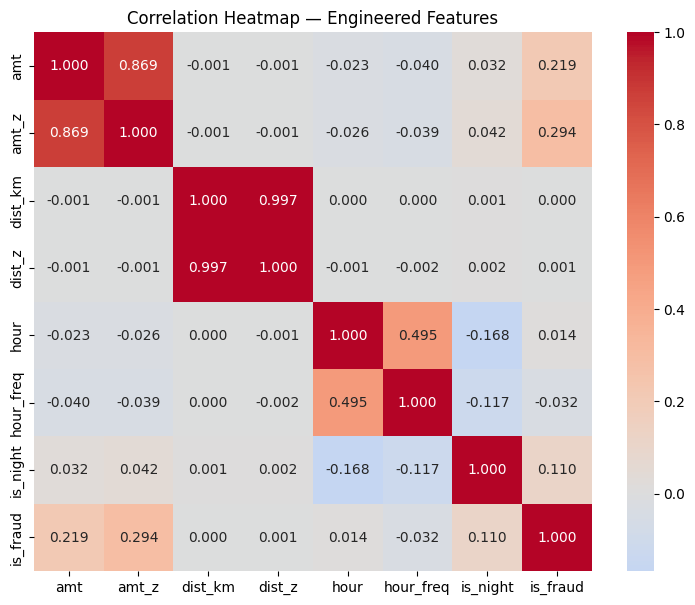

In [21]:
numeric_cols = ['amt', 'amt_z', 'dist_km', 'dist_z', 'hour', 'hour_freq', 'is_night', 'is_fraud']

plt.figure(figsize=(9, 7))
sns.heatmap(train[numeric_cols].corr(), annot=True, fmt='.3f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Engineered Features')
plt.show()

In [22]:
def haversine_distance(lat1, long1, lat2, long2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dl = np.radians(long2 - long1)
    a = np.sin((p2 - p1) / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def test_customer_transaction(user_id, amt, timestamp, cust_lat, cust_long, merch_lat, merch_long, category):
    profile = base[base['user_id'] == user_id]

    if profile.empty:
        print(f"{user_id} was not found.")
        return

    timestamp = pd.to_datetime(timestamp)
    hour = timestamp.hour

    amt_mean = profile['amt_mean'].iloc[0]
    amt_std = profile['amt_std'].iloc[0]
    dist_mean = profile['dist_mean'].iloc[0]
    dist_std = profile['dist_std'].iloc[0]

    dist_km = haversine_distance(cust_lat, cust_long, merch_lat, merch_long)
    amt_z = (amt - amt_mean) / amt_std
    dist_z = (dist_km - dist_mean) / dist_std
    night = hour >= 22 or hour <= 3

    prob, verdict = score_transaction(
        user_id=user_id, amt=amt, timestamp=timestamp,
        cust_lat=cust_lat, cust_long=cust_long,
        merch_lat=merch_lat, merch_long=merch_long, category=category
    )

    print("=" * 60)
    print("CUSTOMER TRANSACTION TEST")
    print("=" * 60)
    print(f"\nCustomer: {user_id}")

    print("\n--- Customer's Typical Behaviour ---")
    print(f"Typical transaction amount: R{amt_mean:.2f}")
    print(f"Amount standard deviation: R{amt_std:.2f}")
    print(f"Typical transaction distance: {dist_mean:.2f} km")
    print(f"Distance standard deviation: {dist_std:.2f} km")

    print("\n--- New Transaction ---")
    print(f"Transaction amount: R{amt:.2f}")
    print(f"Amount deviation (z-score): {amt_z:.2f}")
    print(f"Transaction distance: {dist_km:.2f} km")
    print(f"Distance deviation (z-score): {dist_z:.2f}")
    print(f"Transaction time: {timestamp}")
    print(f"Hour: {hour}:00")
    print(f"Unusual hour: {'Yes' if night else 'No'}")
    print(f"Category: {category}")

    print("\n--- Model Decision ---")
    print(f"Fraud probability: {prob:.2%}")
    print(f"Final verdict: {verdict.upper()}")
    print("=" * 60)

    return {
        "user_id": user_id, "typical_amount": amt_mean, "amount_std": amt_std,
        "transaction_amount": amt, "amount_z": amt_z, "typical_distance_km": dist_mean,
        "transaction_distance_km": dist_km, "distance_z": dist_z, "timestamp": timestamp,
        "category": category, "fraud_probability": prob, "verdict": verdict.upper()
    }

In [25]:
test_customer_transaction(
    user_id='User_8', amt=1152, timestamp='2020-08-15 02:30',
    cust_lat=-26.2041, cust_long=28.0473,
    merch_lat=-26.1367, merch_long=28.1882, category='shopping_net'
)

CUSTOMER TRANSACTION TEST

Customer: User_8

--- Customer's Typical Behaviour ---
Typical transaction amount: R65.34
Amount standard deviation: R102.77
Typical transaction distance: 76.26 km
Distance standard deviation: 29.83 km

--- New Transaction ---
Transaction amount: R1152.00
Amount deviation (z-score): 10.57
Transaction distance: 15.93 km
Distance deviation (z-score): -2.02
Transaction time: 2020-08-15 02:30:00
Hour: 2:00
Unusual hour: Yes
Category: shopping_net

--- Model Decision ---
Fraud probability: 86.11%
Final verdict: FRAUD


{'user_id': 'User_8',
 'typical_amount': np.float64(65.34296046287366),
 'amount_std': np.float64(102.76998817791207),
 'transaction_amount': 1152,
 'amount_z': np.float64(10.573680690280327),
 'typical_distance_km': np.float64(76.25957465646265),
 'transaction_distance_km': np.float64(15.933822108891064),
 'distance_z': np.float64(-2.0223051045354565),
 'timestamp': Timestamp('2020-08-15 02:30:00'),
 'category': 'shopping_net',
 'fraud_probability': np.float32(0.86106193),
 'verdict': 'FRAUD'}

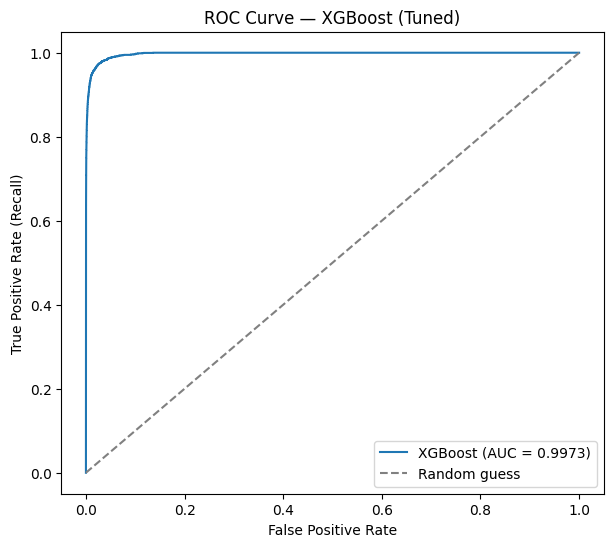

In [26]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, probs_t)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, probs_t):.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve — XGBoost (Tuned)')
plt.legend()
plt.show()